## Análisis de Datos Meteorológicos con una API Pública
Obtener datos del clima de una ciudad usando la API de Open-Meteo (https://open-meteo.com/) y mostrar el pronóstico para Bilbao.

* Haz una petición a la API para que devuelva el pronóstico de las temperaturas para una semana en Bilbao. Tip: el parámetro correspondiente en el query es `temperature_2m` además de la latitud y la longitud.
* Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
* Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`
* Elige la gráfica adecuada y visualiza el pronóstico de temperaturas.

Para crear la variable `Hora` del DataFrame puedes introducir directamente la lista que se obtiene del campo `data["hourly"]["time"]` o procesar esa lista mediante el siguiente código:

`hours = pd.date_range(start=lista_de_horas, periods=len(temps), freq="H")`

168 168
['2026-11-08T00:00', '2026-11-08T01:00', '2026-11-08T02:00'] [14.8, 15.3, 15.6]


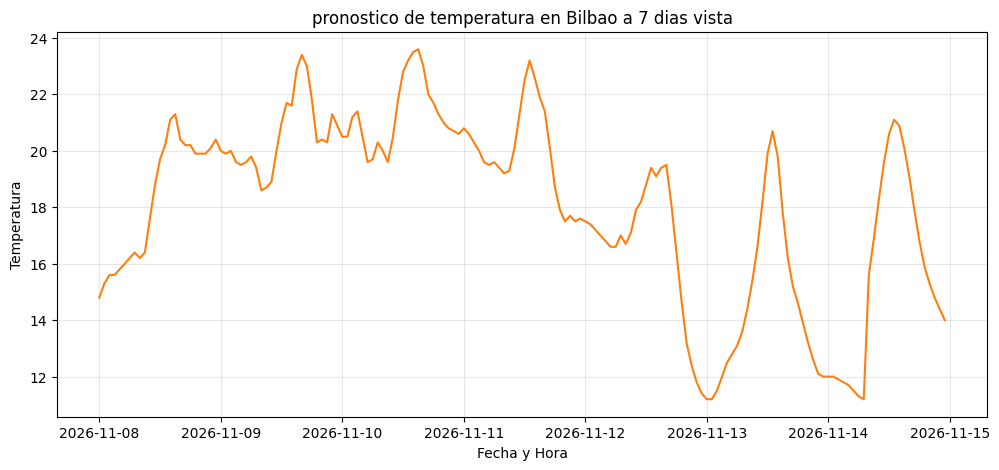

In [4]:
import requests

import pandas as pd
import matplotlib.pyplot as plt

# Coordenadas de Kuna en Bilbao
latitude = 43.2540
longitude = -2.9230


url = f"https://api.open-meteo.com/v1/forecast?latitude={latitude}&longitude={longitude}&hourly=temperature_2m&forecast_days=7&timezone=Europe%2FMadrid"  #crear url para pasar introduciendo los datos qye se buscan con las variables 'longitud, latitud'

respuesta = requests.get(url)  #guardar respuesta de la api
respuesta.status_code

data = respuesta.json()   #guardar respuesta como json
data.keys()    #explorar respuesta de la api mediante sus claves de diccionario
horas = data["hourly"]["time"]
temps = data["hourly"]["temperature_2m"]           #concretar datos que buscamos

print(len(horas), len(temps))
print(horas[:3], temps[:3])



hours = pd.date_range(start=horas[0], periods=len(temps), freq="h")       #generar 168 horas seguidas a partir de la primera fecha en formato fecha

df = pd.DataFrame({
    "Hora": hours,                                      #pasar a dataframe la dara obtenida en forma de dias/horas y temperaturas
    "Temperatura": temps
})
df.head()

df.describe()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df["Hora"], df["Temperatura"], color="tab:orange")               #representar dataset, eje x saca del dataset las fechas, eje y establece la temperatura
ax.set_title("pronostico de temperatura en Bilbao a 7 dias vista")
ax.set_xlabel("Fecha y Hora")
ax.set_ylabel("Temperatura")
ax.grid(alpha=0.3)
plt.show()